# 06 — Part 3 validation evaluation

Loads `reports/evaluation/part3_validation.json` produced by `scripts/evaluate.py`.
Does not retrain and does not touch the test set.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
payload = json.loads((ROOT / "reports" / "evaluation" / "part3_validation.json").read_text(encoding="utf-8"))
print("split:", payload["split"], "device:", payload["device"], payload.get("gpu"))
print("test set used in this file:", False)
for row in payload["comparison"]:
    print("{model:16} acc={accuracy:.4f} macroF1={macro_f1:.4f} mildF1={mild_f1:.4f} params={parameters}".format(**row))


split: val device: cuda NVIDIA GeForce RTX 3050 Ti Laptop GPU
test set used in this file: False
baseline         acc=0.4953 macroF1=0.4374 mildF1=0.2111 params=12547
custom_cnn       acc=0.5853 macroF1=0.5099 mildF1=0.2362 params=1173987
resnet50         acc=0.7804 macroF1=0.6458 mildF1=0.3159 params=23514179
efficientnet_b0  acc=0.7658 macroF1=0.6532 mildF1=0.3528 params=4011391


In [2]:
print("Part 2 match (atol 0.002):")
for model, keys in payload["part2_match"].items():
    ok = all(v["ok"] for v in keys.values())
    worst = max(v["abs_delta"] for v in keys.values())
    print(f"  {model:16} all_ok={ok} max_abs_delta={worst:.6f}")
print("\nEfficientNet-B0 mild patterns:")
print(json.dumps({k: payload["mild_errors"]["efficientnet_b0"][k] for k in [
    "mild_true_positives", "false_positives_mild", "false_negatives_mild",
    "mild_predicted_as_little_or_none", "mild_predicted_as_severe",
    "little_or_none_predicted_as_mild", "severe_predicted_as_mild",
]}, indent=2))


Part 2 match (atol 0.002):
  baseline         all_ok=True max_abs_delta=0.000000
  custom_cnn       all_ok=True max_abs_delta=0.000182
  resnet50         all_ok=True max_abs_delta=0.001272
  efficientnet_b0  all_ok=True max_abs_delta=0.001283

EfficientNet-B0 mild patterns:
{
  "mild_true_positives": 275,
  "false_positives_mild": 591,
  "false_negatives_mild": 418,
  "mild_predicted_as_little_or_none": {
    "count": 175,
    "pct_of_mild": 25.252525252525253,
    "pct_of_validation": 2.8557441253263707
  },
  "mild_predicted_as_severe": {
    "count": 243,
    "pct_of_mild": 35.064935064935064,
    "pct_of_validation": 3.965404699738903
  },
  "little_or_none_predicted_as_mild": {
    "count": 293,
    "pct_of_little_or_none": 8.12760055478502,
    "pct_of_validation": 4.781331592689296
  },
  "severe_predicted_as_mild": {
    "count": 298,
    "pct_of_severe": 16.28415300546448,
    "pct_of_validation": 4.862924281984334
  }
}


**efficientnet_b0_cm_normalized.png**

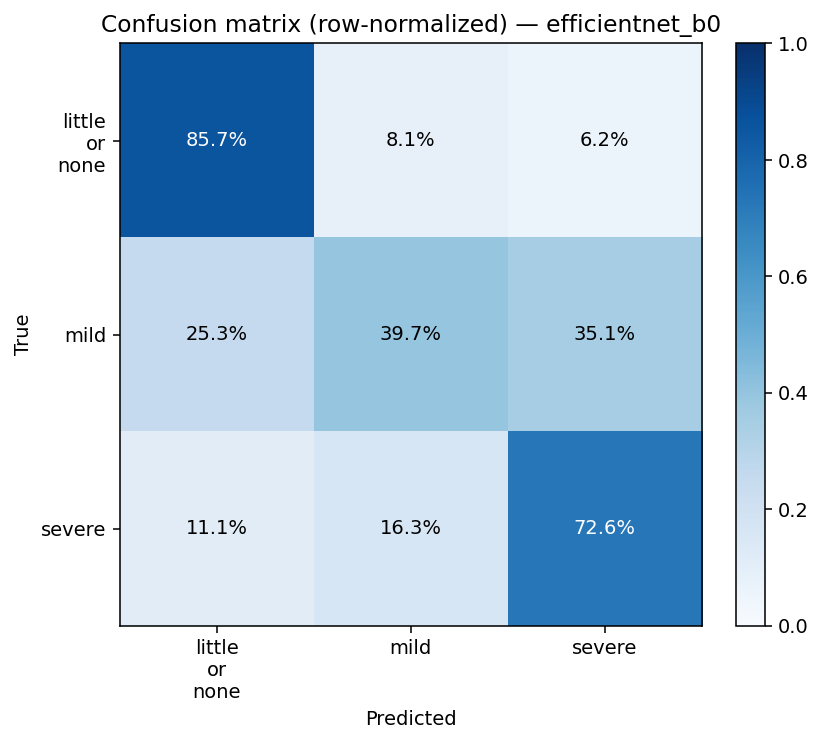

**resnet50_cm_normalized.png**

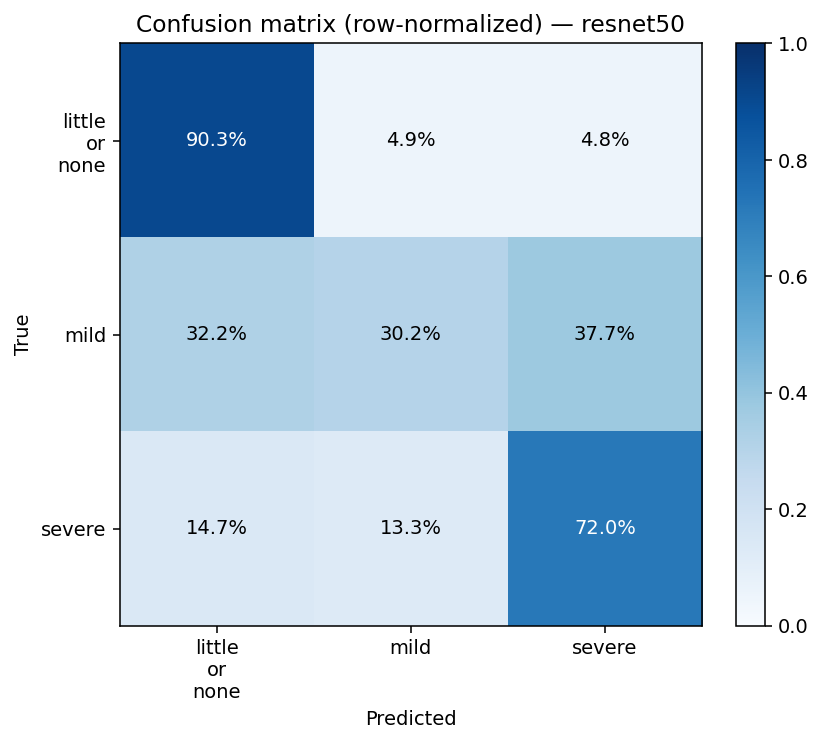

**efficientnet_b0_confidence.png**

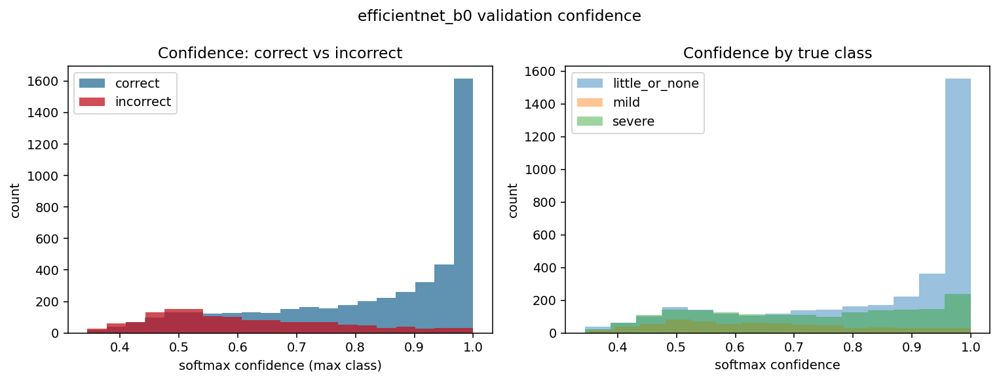

**efficientnet_b0_error_examples.png**

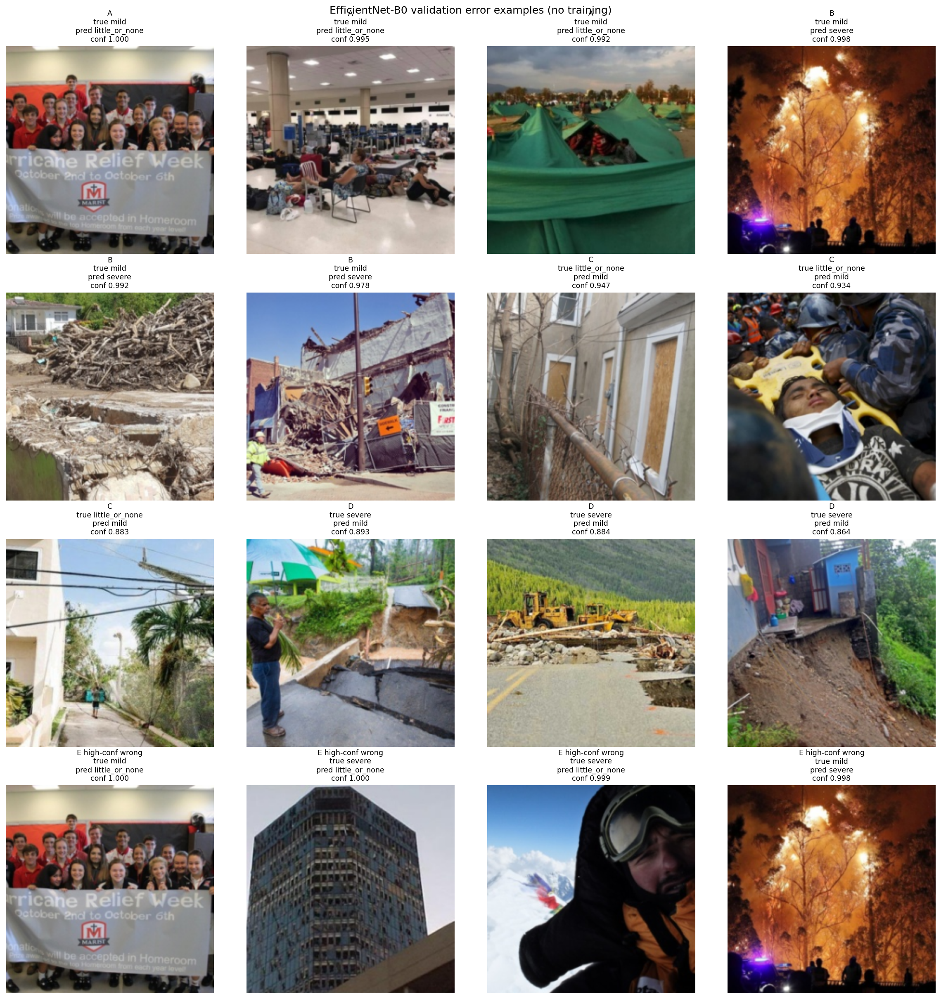

**efficientnet_b0_gradcam.png**

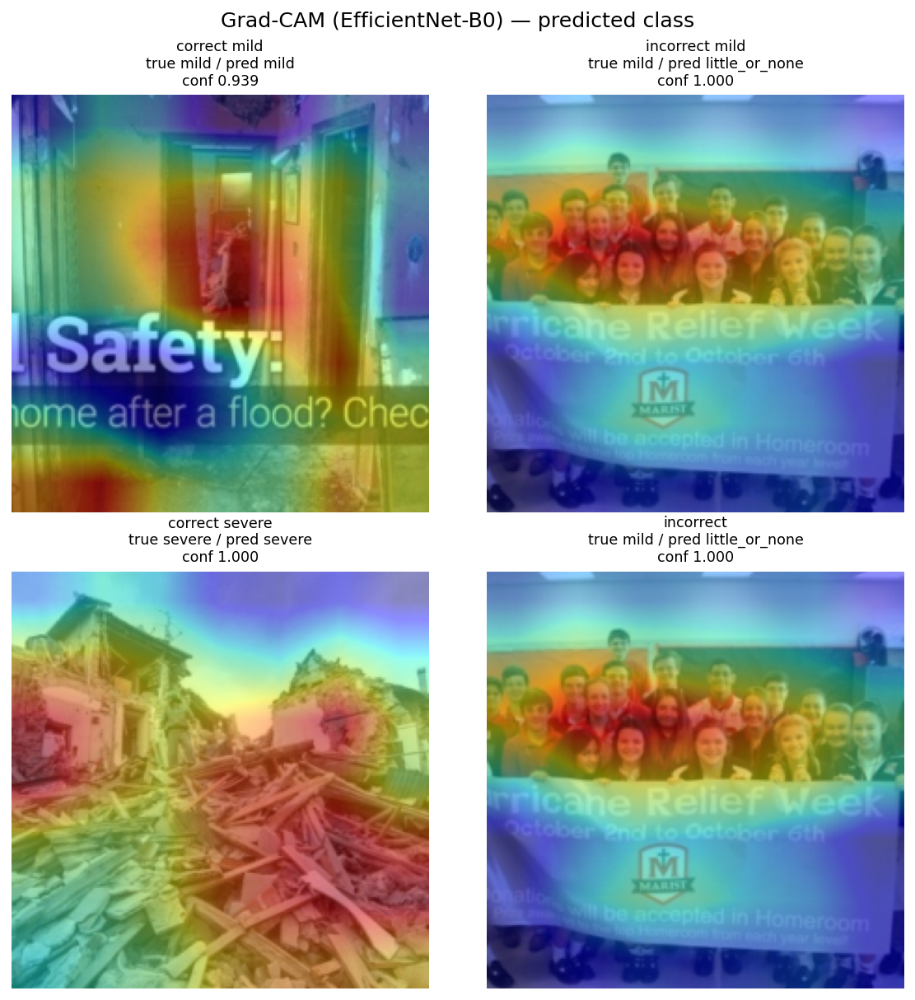

**resnet50_gradcam.png**

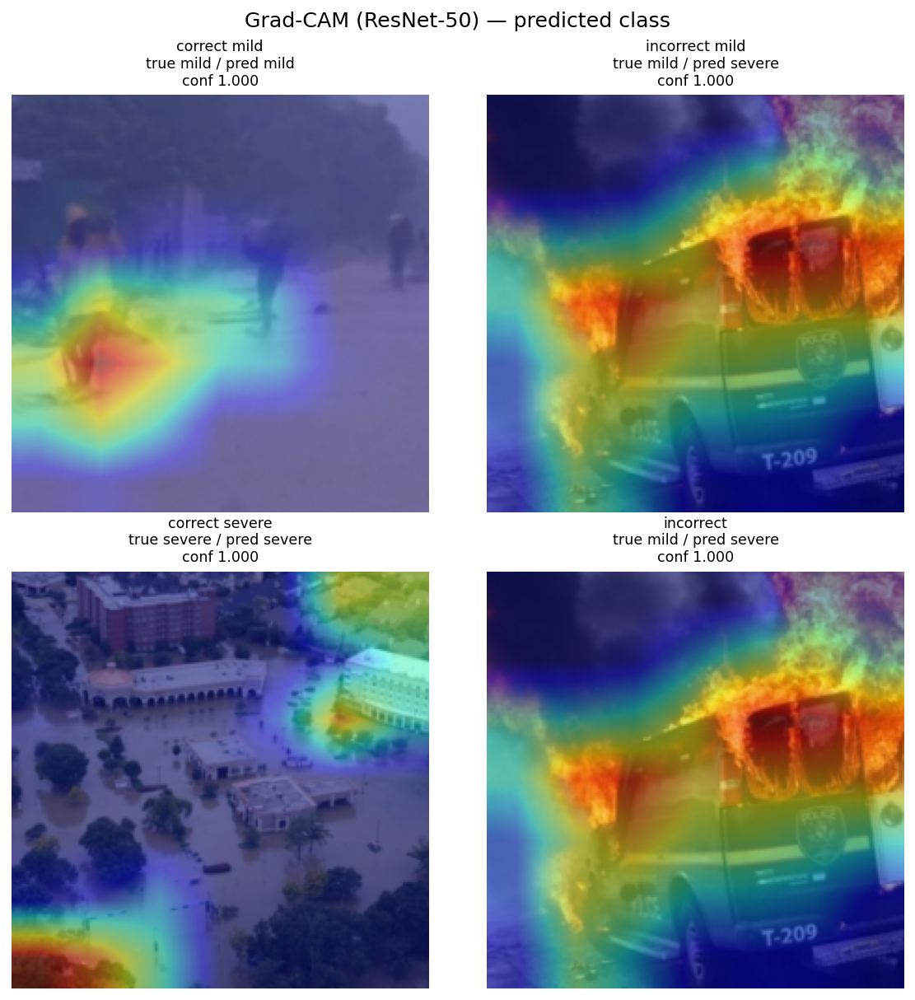

In [3]:
fig = ROOT / "reports" / "figures"
for name in [
    "efficientnet_b0_cm_normalized.png",
    "resnet50_cm_normalized.png",
    "efficientnet_b0_confidence.png",
    "efficientnet_b0_error_examples.png",
    "efficientnet_b0_gradcam.png",
    "resnet50_gradcam.png",
]:
    path = fig / name
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path))) if path.exists() else print("missing", path)
